# 02 · Mô hình phân loại cảm xúc review (Vietnamese Sentiment Classification)

**Mục tiêu.** Dự đoán cảm xúc (negative / neutral / positive) từ *nội dung text*. Ứng dụng:
- gắn nhãn cho phản hồi đến từ kênh **không có số sao** (chat CSKH, mạng xã hội, hotline đã chuyển text);
- phát hiện review mà **số sao mâu thuẫn với nội dung** (vd 5★ nhưng than phiền) để không bỏ sót vấn đề.

**Thiết kế thí nghiệm**
| Quyết định | Lý do |
|---|---|
| Nhãn từ số sao (1–2 / 3 / 4–5) | Weak supervision, không tốn chi phí gán nhãn |
| Chia **theo thời gian** (20% mới nhất làm test) | Mô phỏng triển khai thật; tránh rò rỉ thông tin từ tương lai; đo được *data drift* |
| Metric chính **macro-F1** | Lớp neutral rất hiếm, accuracy sẽ đánh lừa |
| TF-IDF word 1–2 gram + char 2–5 gram | Bigram âm tiết ≈ từ ghép tiếng Việt; char n-gram bền với lỗi chính tả, thiếu dấu |
| `class_weight="balanced"` | Bù mất cân bằng lớp |

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import display, Markdown

from momo_reviews.config import CLEAN_FILE
from momo_reviews.viz import set_style, save, SENTIMENT_COLORS, BLUE, INK_2
set_style()
pd.set_option("display.max_colwidth", 160)

df = pd.read_parquet(CLEAN_FILE)
print(f"{len(df):,} review | {df['at'].min():%d/%m/%Y} → {df['at'].max():%d/%m/%Y}")
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from momo_reviews.model import load_modeling_data, temporal_split, candidate_models, evaluate, top_features, select_model, save_final_model
from momo_reviews.config import SENTIMENT_ORDER, REPORTS_DIR

217,336 review | 28/05/2014 → 22/10/2026


## 1. Dữ liệu huấn luyện

In [2]:
data = load_modeling_data(df)
train, test = temporal_split(data, test_size=0.2)
print(f"Bỏ {len(df)-len(data):,} review rỗng/spam → còn {len(data):,}")
print(f"Train: {len(train):,}  ({train['at'].min():%m/%Y} – {train['at'].max():%m/%Y})")
print(f"Test : {len(test):,}  ({test['at'].min():%m/%Y} – {test['at'].max():%m/%Y})")
pd.DataFrame({"train": train["sentiment"].value_counts(normalize=True),
              "test": test["sentiment"].value_counts(normalize=True)}).loc[SENTIMENT_ORDER].style.format("{:.1%}")

Bỏ 435 review rỗng/spam → còn 216,901
Train: 173,520  (05/2014 – 12/2023)
Test : 43,381  (12/2023 – 10/2026)


,train,test
sentiment,,
negative,36.5%,45.8%
neutral,4.4%,3.3%
positive,59.1%,50.9%


In [3]:
train[["content", "text_clean", "sentiment"]].sample(6, random_state=1)

,content,text_clean,sentiment
155986,Ko tìm dc cho xác nhận khuôn mặt,không tìm được cho xác nhận khuôn mặt,neutral
23219,tốt,tốt,positive
78041,Thanh toán tiền điện Miền Nam ko được v,thanh toán tiền điện miền nam không được vậy,neutral
13504,nuoi trung dsgms jisfbk,nuoi trung dsgms jisfbk,positive
132251,"Chuyển tiền từ momo qa ngân hàng VCB cho bạn bên mình thì báo hoàn tất hết, còn bên kia chưa nhận đc tiền. Hỗ trợ giải quyết thì đòi ra ngân hàng sao kê, có...",chuyển tiền từ momo quá ngân hàng vcb cho bạn bên mình thì báo hoàn tất hết còn bên kia chưa nhận được tiền hỗ trợ giải quyết thì đòi ra ngân hàng sao kê có...,negative
96137,"App Momo mua vietlot không chọn được số tự chọn, muốn mua số theo ý mình mà không được. Nghỉ khỏe",ứng dụng momo mua vietlot không chọn được số tự chọn muốn mua số theo ý mình mà không được nghỉ khỏe,positive


## 2. So sánh mô hình

In [4]:
results, fitted = evaluate(candidate_models(), train, test)
results.to_csv(REPORTS_DIR / "model_comparison.csv", index=False)
results.style.format({c: "{:.3f}" for c in results.columns if c not in ("model", "train_seconds")} | {"train_seconds": "{:.0f}s"}) \
       .background_gradient(subset=["macro_f1"], cmap="Blues").hide(axis="index")

model,macro_f1,weighted_f1,f1_negative,f1_neutral,f1_positive,train_seconds
TF-IDF word+char + LinearSVC,0.655,0.894,0.908,0.128,0.930,523s
TF-IDF word+char + LogReg,0.652,0.882,0.888,0.146,0.923,203s
TF-IDF word + LogReg,0.651,0.881,0.887,0.143,0.922,73s
TF-IDF word + ComplementNB,0.613,0.877,0.897,0.029,0.914,9s
Majority baseline,0.225,0.344,0.000,0.000,0.675,9s


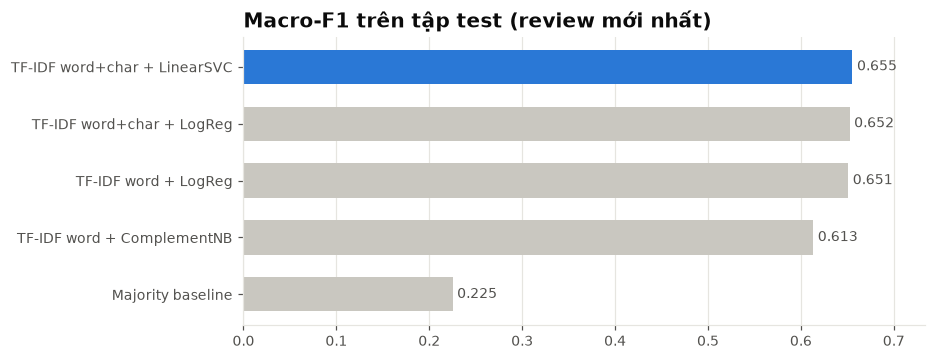

In [5]:
r = results.sort_values("macro_f1")
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(r["model"], r["macro_f1"], color=["#c9c7c0"] * (len(r) - 1) + [BLUE], height=0.6)
for y, v in enumerate(r["macro_f1"]):
    ax.text(v + 0.005, y, f"{v:.3f}", va="center", fontsize=9, color=INK_2)
ax.set_xlim(0, max(r["macro_f1"]) * 1.12); ax.set_title("Macro-F1 trên tập test (review mới nhất)")
ax.grid(axis="y", visible=False)
save(fig, "02_model_comparison"); plt.show()

**Chọn mô hình.** Các mô hình tuyến tính trên TF-IDF cho kết quả rất sát nhau. Quy tắc chọn: *mô hình huấn luyện nhanh nhất trong khoảng 0.5 điểm macro-F1 so với mô hình tốt nhất* — chênh lệch nhỏ hơn mức này không có ý nghĩa thực tế, còn mô hình đơn giản rẻ hơn khi retrain định kỳ và (với Logistic Regression) cho **xác suất** để đặt ngưỡng cảnh báo.

## 3. Đánh giá chi tiết mô hình được chọn

TF-IDF word + LogReg


              precision    recall  f1-score   support

    negative      0.886     0.889     0.887     19855
     neutral      0.108     0.210     0.143      1426
    positive      0.954     0.893     0.922     22100

    accuracy                          0.869     43381
   macro avg      0.649     0.664     0.651     43381
weighted avg      0.895     0.869     0.881     43381



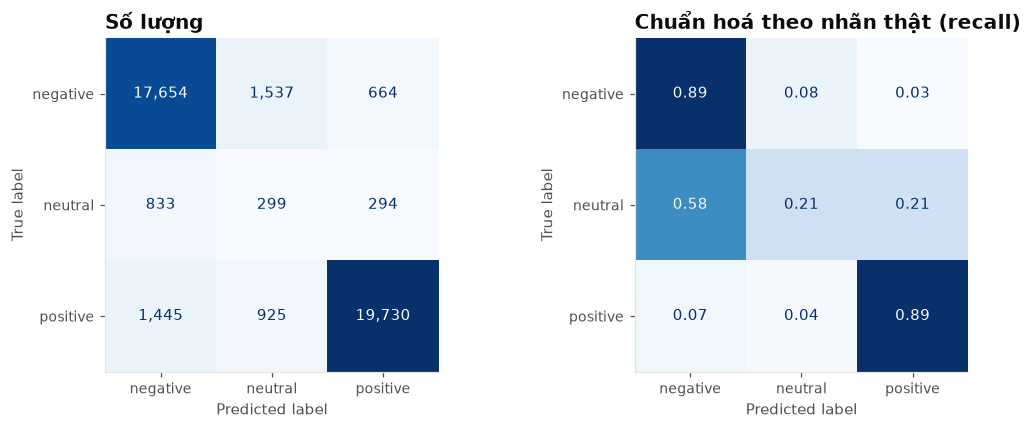

In [6]:
best_name = select_model(results)
best = fitted[best_name]
test = test.assign(pred=best.predict(test["text_clean"]))
print(best_name)
print(classification_report(test["sentiment"], test["pred"], labels=SENTIMENT_ORDER, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, norm, title in [(axes[0], None, "Số lượng"), (axes[1], "true", "Chuẩn hoá theo nhãn thật (recall)")]:
    ConfusionMatrixDisplay.from_predictions(test["sentiment"], test["pred"], labels=SENTIMENT_ORDER, normalize=norm,
                                            cmap="Blues", ax=ax, colorbar=False, values_format=".2f" if norm else ",d")
    ax.set_title(title); ax.grid(False)
fig.tight_layout(); save(fig, "02_confusion_matrix"); plt.show()

**Đọc confusion matrix.** Negative và positive được tách tốt. Neutral là lớp khó nhất — điều này *đúng với bản chất dữ liệu*: review 3★ thường lẫn khen-chê ("app tiện nhưng hay lỗi"), và chính người dùng cũng không nhất quán khi chọn 3★.

### Nếu bỏ lớp neutral?
Trong thực tế, câu hỏi kinh doanh thường là *"review này có phải phàn nàn không?"*. Huấn luyện lại cùng pipeline cho bài toán nhị phân negative vs positive:

In [7]:
from sklearn.base import clone
from sklearn.metrics import f1_score, roc_auc_score
tr_b, te_b = train[train.sentiment != "neutral"], test[test.sentiment != "neutral"]
bin_model = clone(fitted["TF-IDF word+char + LogReg"]).fit(tr_b["text_clean"], tr_b["sentiment"])
proba = bin_model.predict_proba(te_b["text_clean"])[:, list(bin_model.classes_).index("negative")]
y_true = (te_b["sentiment"] == "negative").astype(int)
print(f"Binary  F1(negative) = {f1_score(y_true, proba > 0.5):.3f}   "
      f"macro-F1 = {f1_score(y_true, proba > 0.5, average='macro'):.3f}   ROC-AUC = {roc_auc_score(y_true, proba):.3f}")

Binary  F1(negative) = 0.937   macro-F1 = 0.938   ROC-AUC = 0.975


## 4. Mô hình học được gì? (Explainability)

In [8]:
lr_name = "TF-IDF word + LogReg"
feats = top_features(fitted[lr_name], n=15)[["negative", "positive"]]
feats.index = range(1, len(feats) + 1)
feats

,negative,positive
1,không nên,tiện
2,lừa,không mất
3,rác,vẫn cho
4,không uy,tốt mà
5,dụng tệ,tốt ứng
6,một sao,tiên lỗi
7,bực mình,tien lỗi
8,rất tệ,tuy nhiên
9,mẹ,còn lại
10,nuốt,nhanh gon


Các n-gram có trọng số cao nhất rất "hợp lý nghiệp vụ": lớp negative gắn với *lỗi, không chuyển được, mất tiền, lừa đảo*, lớp positive gắn với *tiện lợi, tốt, nhanh*. Điều này giúp stakeholder tin mô hình và cũng là kiểm tra sanity rằng không học nhầm artefact.

## 5. Error analysis — khi số sao "nói dối"

In [9]:
mismatch = test[(test["sentiment"] == "positive") & (test["pred"] == "negative") & (test["n_words"] >= 6)]
print(f"{len(mismatch):,} review 4–5★ nhưng mô hình đọc nội dung là tiêu cực ({len(mismatch)/len(test):.1%} tập test)")
mismatch.sample(min(8, len(mismatch)), random_state=0)[["score", "content"]]

1,047 review 4–5★ nhưng mô hình đọc nội dung là tiêu cực (2.4% tập test)


,score,content
211266,5,3 tiếng đồng hồ rồi tôi không vào được ứng dụng
205474,5,App lỏ mới với kiếm chuyện lol
207087,5,"Sẵn đây tui chia sẻ ngắn gọn h.thức lừa đảo mới,chuyện là tui xíu nữa bị lọt hố thưởng ví trả sau của momo 2025. Họ sẽ dụ mình chụp điểm uy tín xem có đủ đ...."
208098,5,5.1 món này chán bền bỉ. CCCD Khổng hóng úp 😀
210858,4,Ko tải được trợ thủ AI chỉ sd bình thường thôi
216136,5,"Để được vay ko lãi thì vô trang tên tui, tối đa 5tr9 thôi."
192093,4,xài thanh toán ok. trừ mua vé phim bị delay vé chậm xử lý.
195719,5,Tự nhiên mất hết dử liệu đăng nhập


In [10]:
mismatch2 = test[(test["sentiment"] == "negative") & (test["pred"] == "positive") & (test["n_words"] >= 4)]
print(f"{len(mismatch2):,} review 1–2★ nhưng nội dung tích cực")
mismatch2.sample(min(6, len(mismatch2)), random_state=0)[["score", "content"]]

341 review 1–2★ nhưng nội dung tích cực


,score,content
183614,2,Mặt hơn tương ban
186121,1,App hay có những quả rất không hợp lý
179523,1,Không tốt như mình nghĩ
176160,1,Muon lay lai momo cua
192209,1,tôi thấy dì dùng momo rất tiện lợi cho mọi giao dịch.... tuyệt vời
210458,2,sao nó cứ bị mã qr chưa đa năng v


**Insight quan trọng.** Phần lớn "lỗi" của mô hình thực ra là **nhiễu nhãn**: người dùng cho 5★ nhưng viết lời phàn nàn (hoặc ngược lại). Nếu chỉ nhìn số sao, doanh nghiệp *bỏ sót* những phàn nàn này.
→ Mô hình text-based có giá trị kinh doanh riêng: dùng để **gắn cờ review có sao cao nhưng nội dung tiêu cực** đưa về đội CSKH.
→ Đồng thời cho thấy trần hiệu năng thực tế bị giới hạn bởi chất lượng nhãn, không chỉ bởi mô hình.

## 6. Model có bị "lão hoá" theo thời gian? (drift)

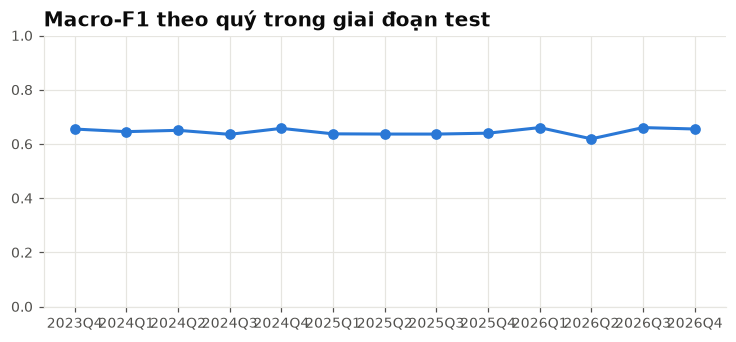

,n,macro_f1
quarter,,
2023Q4,"1,854",0.655
2024Q1,"4,773",0.645
2024Q2,"6,540",0.650
2024Q3,"4,215",0.635
2024Q4,"7,405",0.657
2025Q1,"2,102",0.637
2025Q2,"2,142",0.636
2025Q3,"2,476",0.636
2025Q4,"2,503",0.640


In [11]:
from sklearn.metrics import f1_score
q = test.assign(quarter=test["at"].dt.to_period("Q").astype(str))
drift = q.groupby("quarter").apply(lambda g: pd.Series({"n": len(g),
        "macro_f1": f1_score(g["sentiment"], g["pred"], average="macro")}))
drift = drift[drift["n"] >= 500]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(drift.index, drift["macro_f1"], marker="o", color=BLUE)
ax.set_title("Macro-F1 theo quý trong giai đoạn test"); ax.set_ylim(0, 1)
save(fig, "02_drift"); plt.show()
drift.style.format({"n": "{:,.0f}", "macro_f1": "{:.3f}"})

Hiệu năng giữ ổn định hay giảm dần qua các quý cho biết tần suất cần **retrain**. Trong production, pipeline sẽ crawl review mới hằng tuần, theo dõi metric này và retrain khi giảm quá ngưỡng.

## 7. Lưu mô hình cho app demo (refit trên toàn bộ dữ liệu)

In [12]:
save_final_model(fitted[best_name], data)
print("Đã lưu", best_name)

Đã lưu TF-IDF word + LogReg


## 8. Hướng phát triển
- Fine-tune **PhoBERT** (`vinai/phobert-base-v2`) + word segmentation (VnCoreNLP) — kỳ vọng tăng chủ yếu ở lớp neutral; cần GPU.
- Gán nhãn thủ công ~1–2k review để có tập test "sạch", đo chính xác hơn tác động của nhiễu nhãn.
- Aspect-based sentiment (cảm xúc theo từng khía cạnh) thay vì 1 nhãn/review — xem bước đầu ở notebook 03.